# Example 10 — Run one North Cameroon climate model across years


This example runs one corrected climate-model NetCDF triplet over multiple years in North Cameroon. Each annual worker selects daily rainfall and temperature with `select_daily_window`, prepares model inputs and African soil fields, then calls `run_simulation`. The results section maps mean yield, variability, and trends.

**Inputs:** rainfall, maximum-temperature, and minimum-temperature NetCDF files plus parameter YAML files. **Outputs:** annual yield maps and multi-year statistics. Temperature-based radiation and ET0 estimates are forcing assumptions made in the notebook.


A single corrected rainfall/temperature NetCDF triplet is split into annual seasons. The notebook converts source units, builds the standard xarray input dataset and calls `run_simulation` for each year. It then summarizes the annual maps.


## 1. Import libraries and the model API

In [ ]:
import numpy as np
import datetime
from matplotlib import pyplot as plt
from tqdm import tqdm as tqdm
import xarray as xr
# Import named public functions so the model entry point is visible.
from sarra_py import (
    ModelParameters,
    SimulationConfig,
    calc_day_length_raster_fast,
    load_iSDA_soil_data_alternate,
    load_model_parameters,
    run_simulation,
    select_daily_window,
)
import geopandas as gpd
from joblib import Parallel, delayed
import xarray as xr
import numpy as np
import datetime
from tqdm import tqdm

## 2. Load climate data

In [2]:
# defining the path to the NetCDF datasets
rainfall_data_path = "../data/exemple_data/exemple_10/CDFt_pr_AFR-22_CCCma-CanESM2_rcp85_r1i1p1_CCCma-CanRCM4_v1_day_19800101-20991231.nc"
tmax_data_path = "../data/exemple_data/exemple_10/CDFt_tasmax_AFR-22_CCCma-CanESM2_rcp85_r1i1p1_CCCma-CanRCM4_v0_day_19830101-20991231.nc"
tmin_data_path = "../data/exemple_data/exemple_10/CDFt_tasmin_AFR-22_CCCma-CanESM2_rcp85_r1i1p1_CCCma-CanRCM4_v0_day_19830101-20991231.nc"

In [ ]:
# Open the three daily NetCDF weather variables. 

# rainfall
rainfall_data = xr.open_dataset(rainfall_data_path)
rainfall_data = rainfall_data * 86400.0 # convert from kg m-2 s-1 to mm/day

# tmax
tmax_data = xr.open_dataset(tmax_data_path)
tmax_data = tmax_data["tasmax"] - 273.15 # convert from Kelvin to Celsius

# tmin
tmin_data = xr.open_dataset(tmin_data_path)
tmin_data = tmin_data["tasmin"] - 273.15 # convert from Kelvin to Celsius     

# extractint grid size
grid_width, grid_height = rainfall_data.dims['lat'], rainfall_data.dims['lon']

## 3. Choose parameters and years

In [ ]:
# parameter file names (files are located in the ../data/parameters/ folder)
file_paramVariete = "variety_exemple_2.yaml"
file_paramITK = "itk_exemple_2.yaml"
file_paramTypeSol = "USA_iowa_V42.yaml"

# populate param variables with variety, cropping system and soil parameters
parameters = load_model_parameters(
    f"../data/params/variety/{file_paramVariete}",
    f"../data/params/itk/{file_paramITK}",
    f"../data/params/soil/{file_paramTypeSol}",
)
paramVariete = dict(parameters.variety)
paramITK = dict(parameters.management)
paramTypeSol = dict(parameters.soil)

# Start the water balance on 1 April, before the earliest sowing date.
month_start = 4
day_start = 1

# Earliest eligible sowing date: 1 May.
month_sowing = 5
day_sowing = 1

# Apply the selected calibrated variety parameters.
paramVariete["SDJRPR"] = 489.0
paramVariete["SDJLevee"] = 250.0
paramVariete["SDJBVP"] = 636.0
paramVariete["slaMin"] = 285.0
paramVariete["slaMax"] = 363.2
paramVariete["SDJMatu1"] = 848.0
paramVariete["SDJMatu2"] = 334.0
paramVariete["KRdtPotA"] = 0.9

# Choose the annual seasons to simulate.
years = [year for year in range(1999, 2059)]

# variable à exporter
variable = "rdt"

## 4. Prepare and run one year

In [ ]:
# Build one year of daily forcing before calling the public simulation API.
# Prepare and run one annual season.

def process_year(year):

    # preparing the time slices for yearly simulations
    date_start = datetime.date(year,month_start,day_start)
    duration = 220

    # initialize empty xarray dataset
    base_data = xr.Dataset()

    # feed the base_data with rainfall
    base_data["rain"] = select_daily_window(rainfall_data["pr"], date_start, duration)
    base_data["rain"].attrs = {"units":"mm", "long_name":"rainfall"}

    tmax_data_year = select_daily_window(tmax_data, date_start, duration)
    tmin_data_year = select_daily_window(tmin_data, date_start, duration)
    tmean_data_year = (tmax_data_year + tmin_data_year) / 2.0
    base_data["tpMoy"] = tmean_data_year

    
    # Estimate extraterrestrial radiation Ra (MJ m-2 day-1).
    φ   = np.deg2rad(base_data.lat) # latitudes en rad
    
    doy = tmax_data_year.time.dt.dayofyear

    dr = 1 + 0.033 * np.cos(2*np.pi/365 * doy)
    δ  = 0.409 * np.sin(2*np.pi/365 * doy - 1.39)
    ωs = np.arccos(-np.tan(φ) * np.tan(δ))

    Ra = (24*60/np.pi) * 0.0820 * dr * (
            ωs*np.sin(φ)*np.sin(δ) + np.cos(φ)*np.cos(δ)*np.sin(ωs)
        )

    # Broadcast Ra across longitude to match (time, latitude, longitude).
    Ra = Ra.expand_dims(lon=base_data.lon).transpose('time', 'lat', 'lon')

    # Estimate solar radiation from the temperature range (MJ/m²/day).
    base_data["rg"] = 0.16 * Ra * (tmax_data_year - tmin_data_year)**0.5


    # Estimate Hargreaves reference evapotranspiration (mm/day).
    base_data["ET0"] = 0.0023 * (tmean_data_year + 17.8) * np.sqrt(tmax_data_year - tmin_data_year) * Ra
    base_data["ET0"].attrs = {"units": "mm d-1", "long_name": "ET0 – Hargreaves"}
    

    # renaming coordinates for consistency
    base_data = base_data.rename({'lat': 'y', 'lon': 'x'})

    # Check and set CRS if missing
    if base_data.rio.crs is None:
        base_data = base_data.rio.write_crs("EPSG:4326")  # Replace with correct CRS if known

    # Proceed with loading soil data and calculating day length
    base_data = load_iSDA_soil_data_alternate(base_data, grid_width, grid_height)

    # compute day length raster
    base_data = calc_day_length_raster_fast(base_data, date_start, duration)

    management = dict(paramITK)
    management["DateSemis"] = datetime.date(year, month_sowing, day_sowing)
    data = run_simulation(
        base_data, ModelParameters(paramVariete, management, paramTypeSol),
        SimulationConfig(date_start, duration),
    )

    # Return yield from the final simulated day.
    # Mask pixels outside the study area.
    return xr.where(np.isnan(tmax_data_year[0].rename({'lat': 'y', 'lon': 'x'})), np.nan, data[variable][-1,:,:]).expand_dims(year=[year])


## 5. Run the annual cases

In [6]:
# Parallel execution
results_list = Parallel(n_jobs=8)(
    delayed(process_year)(year) for year in tqdm(years)
)

# Concatenate all results along year dimension
results = xr.concat(results_list, dim="year")

 13%|█▎        | 8/60 [00:00<00:00, 74.05it/s]/home/lavarenne/my_venv/lib/python3.12/site-packages/xarray/core/computation.py:824: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
/home/lavarenne/my_venv/lib/python3.12/site-packages/xarray/core/computation.py:824: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
/home/lavarenne/my_venv/lib/python3.12/site-packages/xarray/core/computation.py:824: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
/home/lavarenne/my_venv/lib/python3.12/site-packages/xarray/core/computation.py:824: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
/home/lavarenne/my_venv/lib/python3.12/site-packages/xarray/core/computation.py:824: RuntimeWarning: invalid value encountered in sqrt
  result_data = func(*input_data)
/home/lavarenne/my_venv/lib/python3.12/site-packages/xarray/core/computation.py:824: RuntimeWarning: invalid 

## 6. Inspect and compare outputs

### Average yield

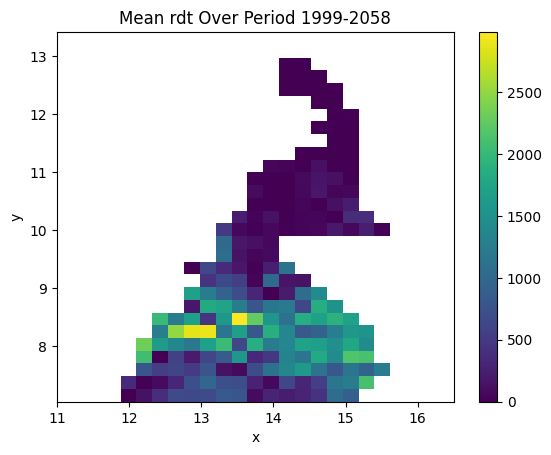

In [10]:
results.mean(axis=0).plot()
plt.title("Mean "+variable+ " Over Period " + str(years[0]) + "-" + str(years[-1]))
plt.show()

### Yield mosaic

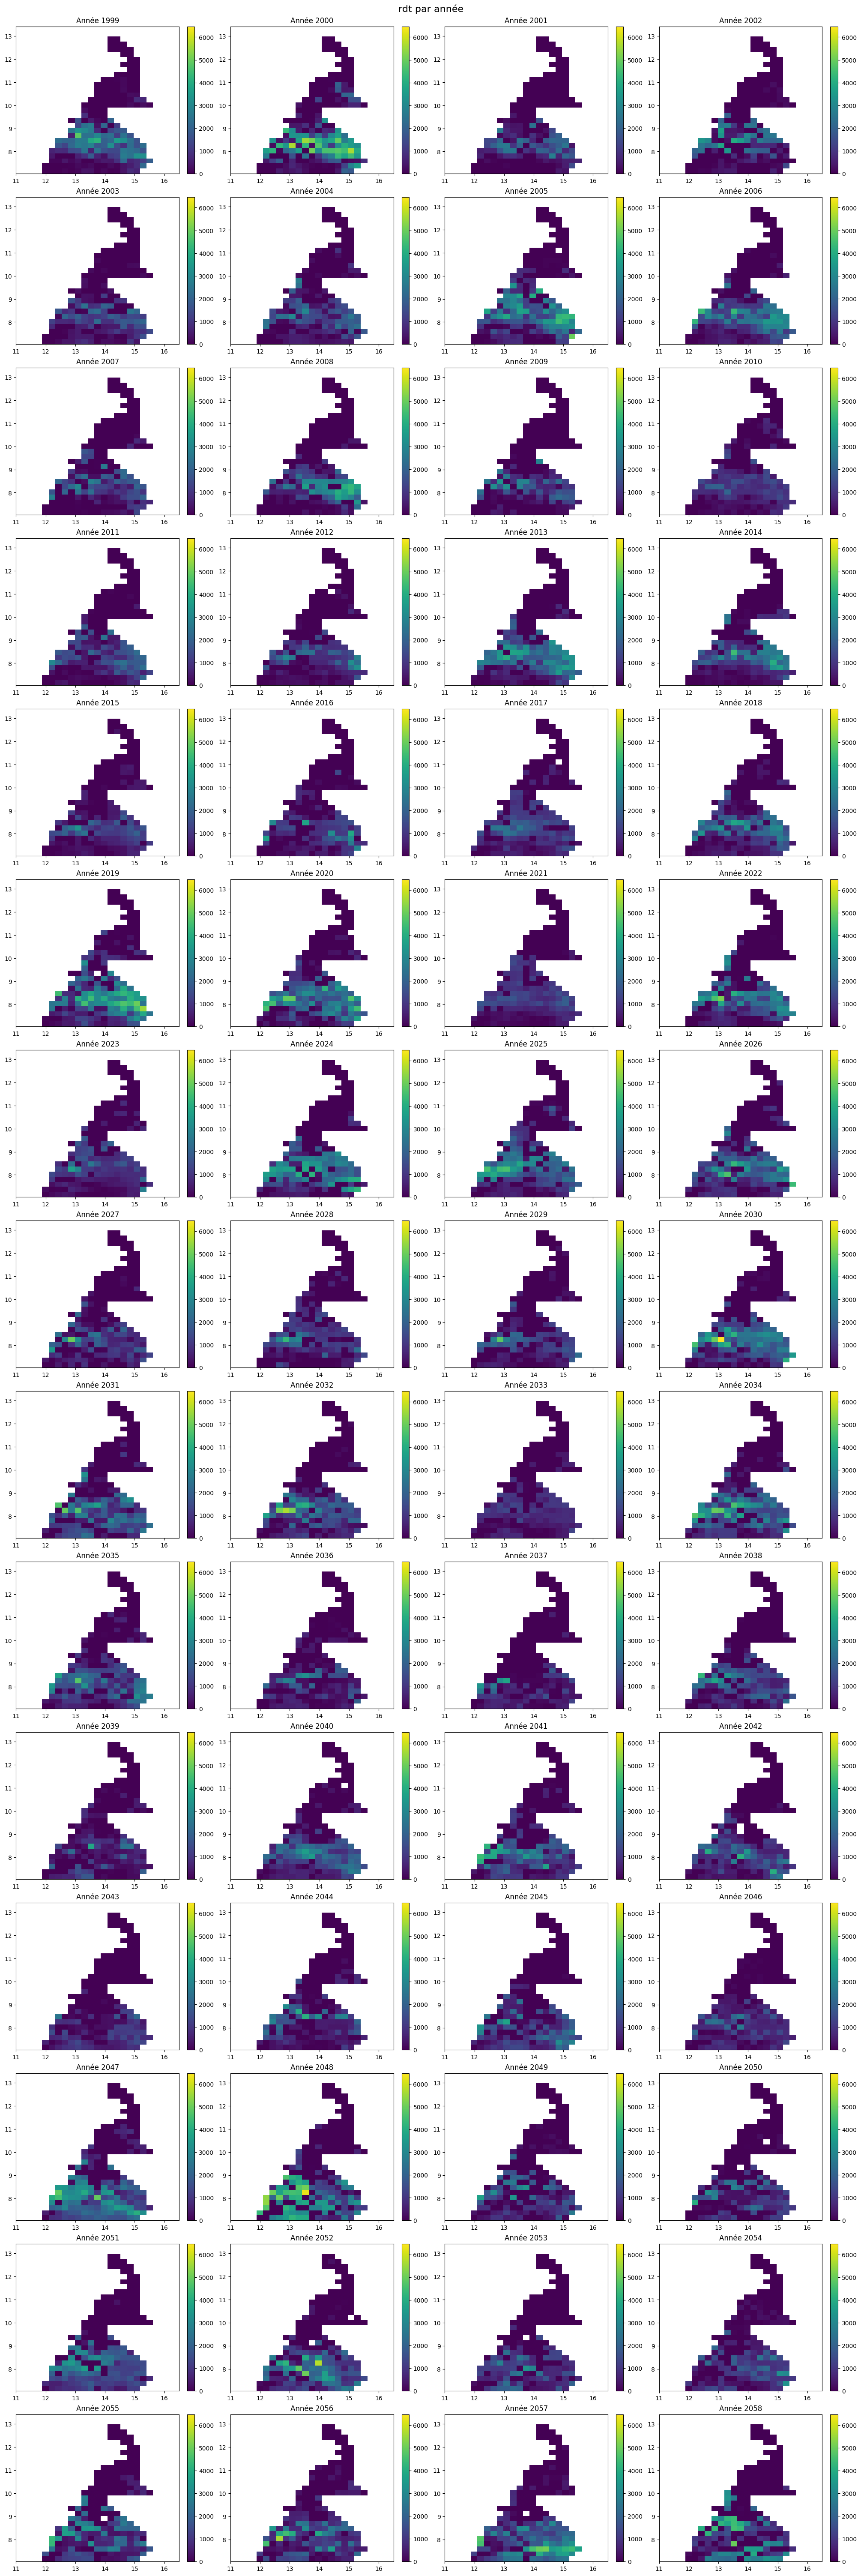

In [11]:
import matplotlib.pyplot as plt

# Number of annual maps.
n_years = results.sizes['year']
years = results['year'].values

# Size the subplot grid for the selected years.
ncols = 4
nrows = int(np.ceil(n_years / ncols))

# Size the figure for the annual panels.
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(5*ncols, 4*nrows), constrained_layout=True)

# Flatten axes to place each annual map.
axes = axes.ravel()

# Plot one map per year.
for i, year in enumerate(years):
    ax = axes[i]
    results.sel(year=year).plot(ax=ax, cmap="viridis", vmin=0, vmax=results.max().values)
    ax.set_title(f"Année {year}")
    ax.set_xlabel("")
    ax.set_ylabel("")

# Hide unused subplot panels.
for j in range(n_years, len(axes)):
    axes[j].axis("off")

plt.suptitle(variable+" par année", fontsize=16)
plt.show()


### Yield variability

/home/lavarenne/my_venv/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2019: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


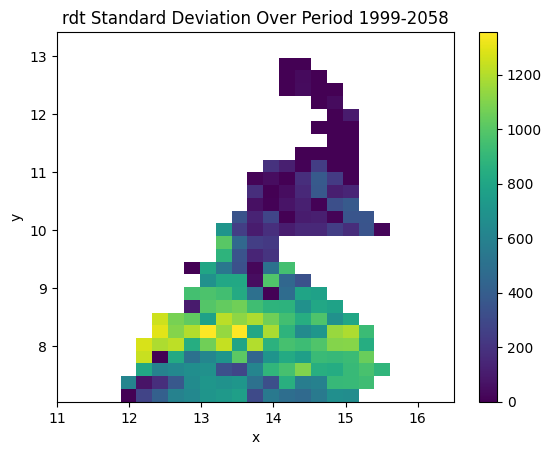

In [9]:
results.std(axis=0).plot()
plt.title(variable+" Standard Deviation Over Period " + str(years[0]) + "-" + str(years[-1]))
plt.show()

### Regional yield over time

In [ ]:
# Flatten each annual yield map to a one-dimensional pixel series.
flattened = results.stack(pixel=("y", "x"))  # dimensions : (year, pixel)

import matplotlib.pyplot as plt

# Extract the year coordinates.
years = results["year"].values

# Prepare one array of pixel yields per year.
box_data = [flattened.sel(year=year).values for year in years]

# Création du boxplot
plt.figure(figsize=(10, 6))
plt.boxplot(box_data, positions=years, widths=0.6, patch_artist=True, showfliers=True)

plt.xlabel("Année")
plt.ylabel("Rendement (unité)")
plt.title("Évolution du rendement moyen spatial par année")
plt.grid(True, linestyle="--", alpha=0.4)
plt.xticks(years, rotation=45)

plt.tight_layout()
plt.show()

### Yield trend

In [5]:
def hamed_rao_with_sen_slope(x):
    x = np.asarray(x)
    x = x[~np.isnan(x)]  # supprime les NaNs
    n = len(x)
    
    if n < 2:
        return np.nan, np.nan, np.nan

    # Sen's slope
    slopes = []
    for i in range(n - 1):
        for j in range(i + 1, n):
            slopes.append((x[j] - x[i]) / (j - i))
    if len(slopes) == 0:
        return np.nan, np.nan, np.nan
    sen_slope = np.median(slopes)

    # Mann-Kendall S
    s = 0
    for k in range(n - 1):
        s += np.sum(np.sign(x[k+1:] - x[k]))

    unique_x, tp = np.unique(x, return_counts=True)
    var_s = (n*(n-1)*(2*n+5) - np.sum(tp*(tp-1)*(2*tp+5))) / 18

    if var_s == 0:
        return np.nan, np.nan, np.nan

    if s > 0:
        z = (s - 1) / np.sqrt(var_s)
    elif s < 0:
        z = (s + 1) / np.sqrt(var_s)
    else:
        z = 0

    p = 2 * (1 - norm.cdf(abs(z)))
    trend = 1.0 if z > 1.96 else -1.0 if z < -1.96 else 0.0

    return sen_slope, p, trend


In [2]:
sen_slope_da, pval_da, trend_da = xr.apply_ufunc(
    hamed_rao_with_sen_slope,
    results,
    input_core_dims=[["year"]],
    output_core_dims=[[], [], []],
    vectorize=True,
    dask="parallelized",
    output_dtypes=[float, float, float], 
)


NameError: name 'xr' is not defined

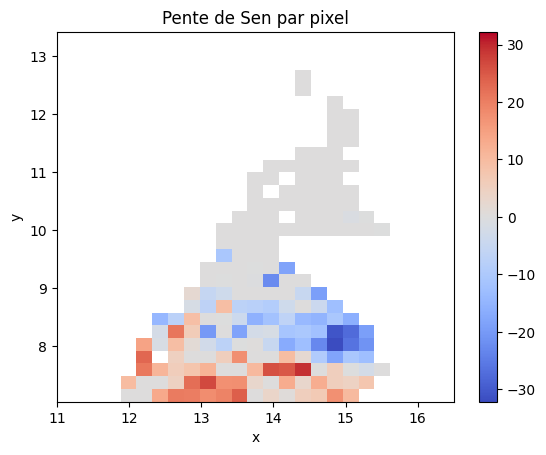

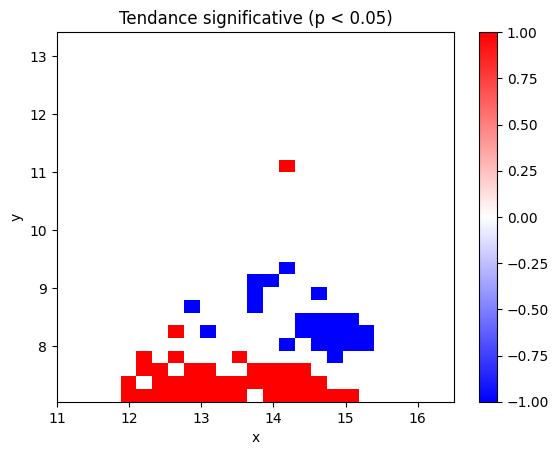

In [22]:
# Carte pente de Sen
sen_slope_da.plot(cmap="coolwarm")
plt.title("Pente de Sen par pixel")
plt.show()

# Carte de tendance significative
trend_da.where(pval_da < 0.05).plot(cmap="bwr", vmin=-1, vmax=1)
plt.title("Tendance significative (p < 0.05)")
plt.show()
